In [167]:
import pandas as pd
import matplotlib.pyplot as plt

In [168]:
df_proficiencia_serasp_2011 = pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2011_1.csv',sep=';',encoding='latin-1')
df_proficiencia_serasp_2012=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2012_1.csv',sep=';',encoding='latin-1')
df_proficiencia_serasp_2013=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2013_1.csv',sep=';',encoding='latin-1')
df_proficiencia_serasp_2014=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2014_1.csv',sep=';',encoding='latin-1')
df_proficiencia_serasp_2015=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2015_1.csv',sep=';',encoding='latin-1')
df_proficiencia_serasp_2016=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2016_1.csv',sep=';',encoding='latin-1')
df_proficiencia_serasp_2017=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2017_0.csv',sep=';',encoding='latin-1')
df_proficiencia_serasp_2018=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2018_0.csv',sep=';',encoding='latin-1')
df_proficiencia_serasp_2019=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2019.csv',sep=';',encoding='latin-1',)
df_proficiencia_serasp_2021=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2021_0.csv',sep=';',encoding='latin-1')
df_proficiencia_serasp_2022=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2022_0.csv',sep=';',encoding='latin-1')
df_proficiencia_serasp_2023=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2023.csv',sep=';',encoding='utf-8')
df_proficiencia_serasp_2024=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2024_0.csv',sep=';',encoding='latin-1')
df_proficiencia_serasp_2025=pd.read_csv('../Proficiência do SARESP por Escola/Proficiência do SARESP por Escola de 2025_0.csv',sep=';',encoding='utf-8')

In [169]:
list_proficiencia_saresp=[df_proficiencia_serasp_2011,df_proficiencia_serasp_2012,df_proficiencia_serasp_2013,df_proficiencia_serasp_2014,df_proficiencia_serasp_2015,df_proficiencia_serasp_2016,df_proficiencia_serasp_2017,df_proficiencia_serasp_2018,df_proficiencia_serasp_2019,df_proficiencia_serasp_2021,df_proficiencia_serasp_2022,df_proficiencia_serasp_2023,df_proficiencia_serasp_2024,df_proficiencia_serasp_2025]

In [170]:
for dataframe in list_proficiencia_saresp:
    for coluna in dataframe:
        if coluna== 'MEDPROF':
            dataframe['MEDPROF-N'] = pd.to_numeric(
            dataframe['MEDPROF'].astype(str).str.replace(',', '.', regex=False),
            errors='raise')
        if coluna== 'medprof':
            dataframe['MEDPROF-N'] = pd.to_numeric(
            dataframe['medprof'].astype(str).str.replace(',', '.', regex=False),
            errors='raise')


In [171]:

series = ['7º Ano EF', '9º Ano EF', 'EM-3ª série', '5º Ano EF']

cont = 2011
lista_dataframes = []

# Dicionário para corrigir problemas de codificação
correcao_series = {
    'EM-3Âª sÃ©rie': 'EM-3ª série',
    '7Âº Ano EF': '7º Ano EF',
    '5Âº Ano EF': '5º Ano EF',
    '9Âº Ano EF': '9º Ano EF',
    '3Âº Ano EF': '3º Ano EF'
}

for dataframe in list_proficiencia_saresp:

    if cont == 2020:
        cont += 1

    dataframe.columns = dataframe.columns.str.strip()

    colunas = {col.upper(): col for col in dataframe.columns}

    if 'DS_COMP' in colunas:

        coluna_comp = colunas['DS_COMP']

        if all(col in dataframe.columns for col in ['MEDPROF-N', 'SERIE_ANO']):

            x = dataframe.loc[
                dataframe[coluna_comp].astype(str).str.strip().str.upper() == 'MATEMÁTICA',
                ['MEDPROF-N', 'SERIE_ANO']
            ].copy()

            # Corrige os problemas de codificação da série
            x['SERIE_ANO'] = (
                x['SERIE_ANO']
                .astype(str)
                .str.strip()
                .replace(correcao_series)
            )

            x['ANO'] = cont

            x['MEDPROF-N'] = x['MEDPROF-N'].fillna(
                x['MEDPROF-N'].mean()
            )

            lista_dataframes.append(x)

        else:
            print(f'Ano {cont}: colunas ausentes.')

    else:
        print(f'Ano {cont}: coluna DS_COMP não encontrada.')

    cont += 1


In [172]:
lista_dataframes

[        MEDPROF-N    SERIE_ANO   ANO
 1           207.2    7º Ano EF  2011
 5           207.2    7º Ano EF  2011
 9           238.3    9º Ano EF  2011
 13          238.3    9º Ano EF  2011
 17          282.0  EM-3ª série  2011
 ...           ...          ...   ...
 139045      169.2    5º Ano EF  2011
 139047      213.9    5º Ano EF  2011
 139049      213.9    5º Ano EF  2011
 139051      213.1    5º Ano EF  2011
 139053      213.1    5º Ano EF  2011
 
 [40399 rows x 3 columns],
         MEDPROF-N    SERIE_ANO   ANO
 1           217.9    7º Ano EF  2012
 4           217.9    7º Ano EF  2012
 7           230.1    9º Ano EF  2012
 10          230.1    9º Ano EF  2012
 13          281.4  EM-3ª série  2012
 ...           ...          ...   ...
 110007      236.3    9º Ano EF  2012
 110010      211.2    5º Ano EF  2012
 110012      211.2    5º Ano EF  2012
 110014      205.0    5º Ano EF  2012
 110016      205.0    5º Ano EF  2012
 
 [40355 rows x 3 columns],
         MEDPROF-N  SERIE_ANO 

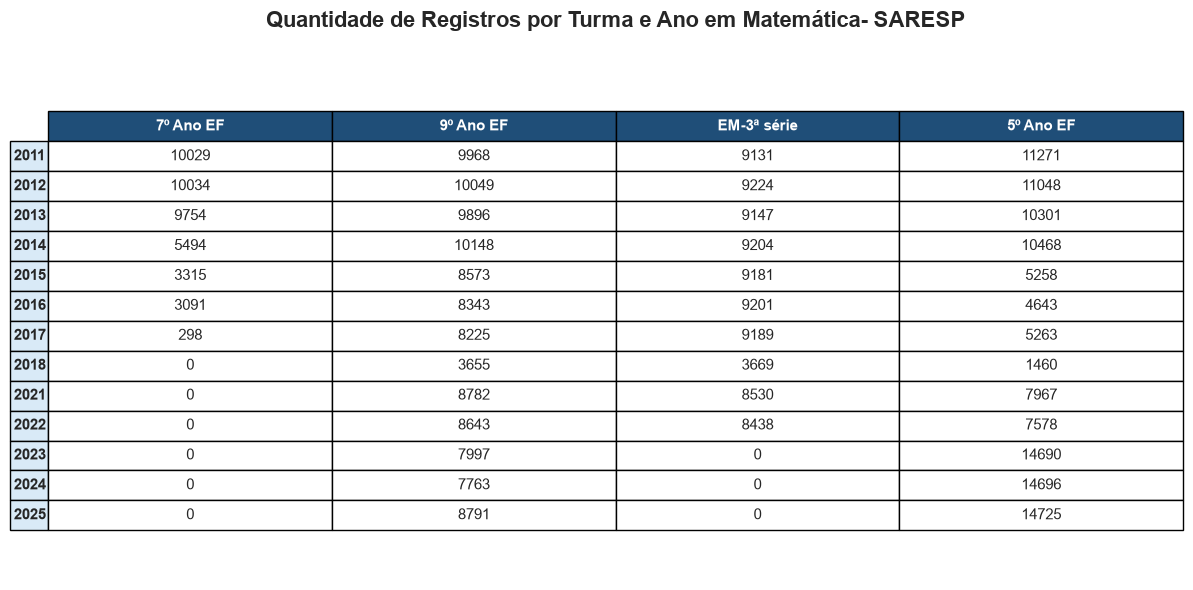

In [183]:
# Concatena os DataFrames
df_total = pd.concat(lista_dataframes, ignore_index=True)

# Conta as turmas por ano
contagem_por_ano = pd.crosstab(
    df_total['ANO'],
    df_total['SERIE_ANO']
)

# Organiza as colunas na ordem desejada
contagem_por_ano = contagem_por_ano.reindex(columns=series, fill_value=0)

# Cria a figura
fig, ax = plt.subplots(figsize=(12, 6))

# Remove os eixos
ax.axis('off')

# Título
ax.set_title(
    'Quantidade de Registros por Turma e Ano em Matemática- SARESP',
    fontsize=16,
    fontweight='bold',
    pad=25
)

# Cria a tabela
tabela = ax.table(
    cellText=contagem_por_ano.values,
    rowLabels=contagem_por_ano.index,
    colLabels=contagem_por_ano.columns,
    cellLoc='center',
    loc='center'
)

# Formatação
tabela.auto_set_font_size(False)
tabela.set_fontsize(11)
tabela.scale(1.2, 1.6)

# Destaca o cabeçalho
for (linha, coluna), celula in tabela.get_celld().items():
    if linha == 0:
        celula.set_facecolor('#1F4E78')
        celula.set_text_props(color='white', weight='bold')
    elif coluna == -1:
        celula.set_facecolor('#D9EAF7')
        celula.set_text_props(weight='bold')

# Ajusta layout
plt.tight_layout()

# Salva em PNG com alta resolução
plt.savefig(
 'contagem_turmas_por_ano.png',
 dpi=300,
 bbox_inches='tight',
 facecolor='white'
)

plt.show()

In [174]:
df_unificado = pd.concat(lista_dataframes, ignore_index=True)
df_unificado['ANO'].value_counts()

ANO
2014    46415
2011    40399
2012    40355
2013    39098
2025    38262
2023    37448
2024    37160
2022    32141
2015    31857
2016    30059
2017    28444
2021    25279
2018    10191
Name: count, dtype: int64

In [175]:
df_unificado


,MEDPROF-N,SERIE_ANO,ANO
0,207.2,7º Ano EF,2011
1,207.2,7º Ano EF,2011
2,238.3,9º Ano EF,2011
3,238.3,9º Ano EF,2011
4,282.0,EM-3ª série,2011
...,...,...,...
437103,228.4,5º Ano EF,2025
437104,161.2,2º Ano EF,2025
437105,161.2,2º Ano EF,2025
437106,208.1,5º Ano EF,2025


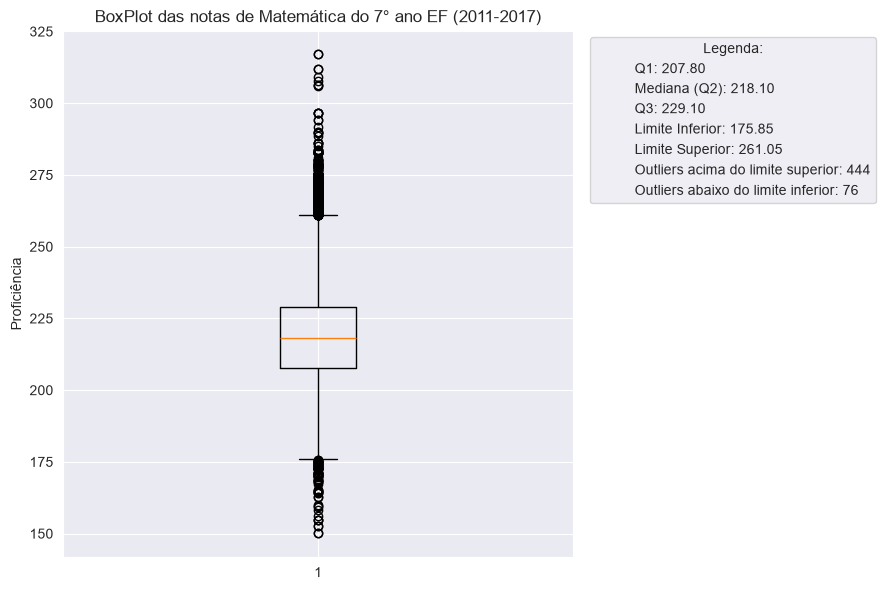

In [184]:
plt.figure(figsize=(9, 6))
x=df_unificado.loc[df_unificado['SERIE_ANO']=='7º Ano EF','MEDPROF-N']

Q1 = x.quantile(0.25)
Q3 = x.quantile(0.75)
IQR = Q3 - Q1
Q2=x.median()

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = x[(x < limite_inferior) | (x > limite_superior)]

outliers_acima = (x > limite_superior).sum()
outliers_abaixo = (x < limite_inferior).sum()

plt.boxplot(x)

plt.title("BoxPlot das notas de Matemática do 7° ano EF (2011-2017)")
plt.ylabel('Proficiência')

plt.plot([], [], ' ', label=f'Q1: {Q1:.2f}')
plt.plot([], [], ' ', label=f'Mediana (Q2): {Q2:.2f}')
plt.plot([], [], ' ', label=f'Q3: {Q3:.2f}')
plt.plot([], [], ' ', label=f'Limite Inferior: {limite_inferior:.2f}')
plt.plot([], [], ' ', label=f'Limite Superior: {limite_superior:.2f}')
plt.plot([], [], ' ', label=f'Outliers acima do limite superior: {outliers_acima}')
plt.plot([], [], ' ', label=f'Outliers abaixo do limite inferior: {outliers_abaixo}')

plt.legend(title='Legenda:',loc='upper left', bbox_to_anchor=(1.02, 1))
plt.savefig(
 'BoxPlot das notas de Matemática do 7° ano EF (2011-2017).png',
 dpi=300,
 bbox_inches='tight',
 facecolor='white'
)

plt.tight_layout()
plt.show()

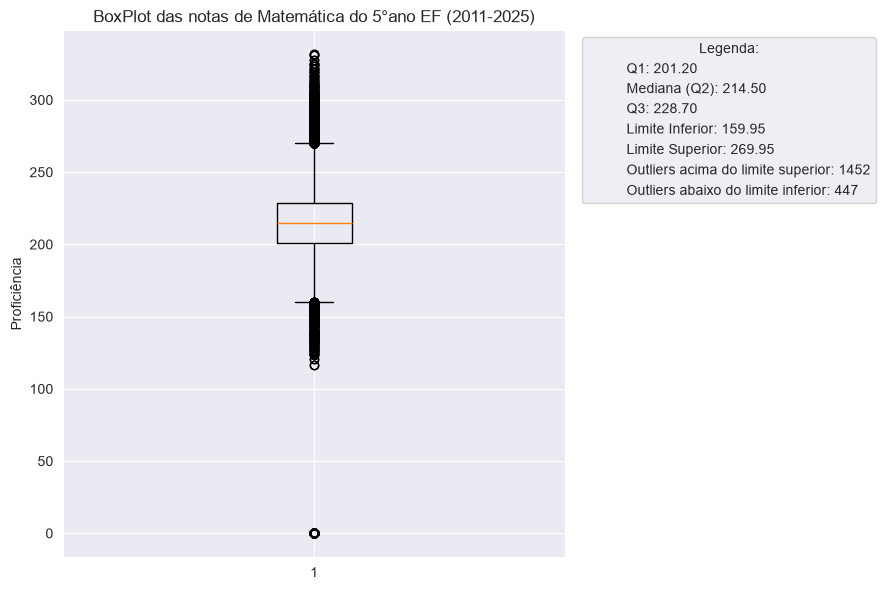

In [185]:
plt.figure(figsize=(9, 6))
x=df_unificado.loc[df_unificado['SERIE_ANO']=='5º Ano EF','MEDPROF-N']

Q1 = x.quantile(0.25)
Q3 = x.quantile(0.75)
IQR = Q3 - Q1
Q2=x.median()

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = x[(x < limite_inferior) | (x > limite_superior)]

outliers_acima = (x > limite_superior).sum()
outliers_abaixo = (x < limite_inferior).sum()

plt.boxplot(x)

plt.title("BoxPlot das notas de Matemática do 5°ano EF (2011-2025)")
plt.ylabel('Proficiência')

plt.plot([], [], ' ', label=f'Q1: {Q1:.2f}')
plt.plot([], [], ' ', label=f'Mediana (Q2): {Q2:.2f}')
plt.plot([], [], ' ', label=f'Q3: {Q3:.2f}')
plt.plot([], [], ' ', label=f'Limite Inferior: {limite_inferior:.2f}')
plt.plot([], [], ' ', label=f'Limite Superior: {limite_superior:.2f}')
plt.plot([], [], ' ', label=f'Outliers acima do limite superior: {outliers_acima}')
plt.plot([], [], ' ', label=f'Outliers abaixo do limite inferior: {outliers_abaixo}')

plt.legend(title='Legenda:',loc='upper left', bbox_to_anchor=(1.02, 1))
plt.tight_layout()

plt.savefig(
 'BoxPlot das notas de Matemática do 5°ano EF (2011-2025).png',
 dpi=300,
 bbox_inches='tight',
 facecolor='white'
)
plt.show()

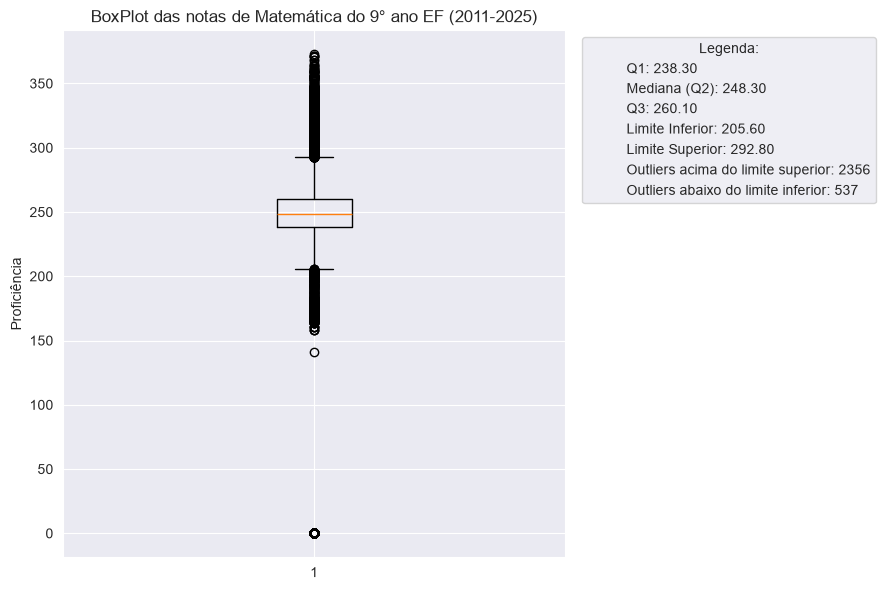

In [186]:
plt.figure(figsize=(9, 6))
x=df_unificado.loc[df_unificado['SERIE_ANO']=='9º Ano EF','MEDPROF-N']

Q1 = x.quantile(0.25)
Q3 = x.quantile(0.75)
IQR = Q3 - Q1
Q2=x.median()

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = x[(x < limite_inferior) | (x > limite_superior)]

outliers_acima = (x > limite_superior).sum()
outliers_abaixo = (x < limite_inferior).sum()

plt.boxplot(x)

plt.title("BoxPlot das notas de Matemática do 9° ano EF (2011-2025)")
plt.ylabel('Proficiência')

plt.plot([], [], ' ', label=f'Q1: {Q1:.2f}')
plt.plot([], [], ' ', label=f'Mediana (Q2): {Q2:.2f}')
plt.plot([], [], ' ', label=f'Q3: {Q3:.2f}')
plt.plot([], [], ' ', label=f'Limite Inferior: {limite_inferior:.2f}')
plt.plot([], [], ' ', label=f'Limite Superior: {limite_superior:.2f}')
plt.plot([], [], ' ', label=f'Outliers acima do limite superior: {outliers_acima}')
plt.plot([], [], ' ', label=f'Outliers abaixo do limite inferior: {outliers_abaixo}')

plt.legend(title='Legenda:',loc='upper left', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.savefig(
 'BoxPlot das notas de Matemática do 9° ano EF (2011-2025).png',
 dpi=300,
 bbox_inches='tight',
 facecolor='white'
)
plt.show()

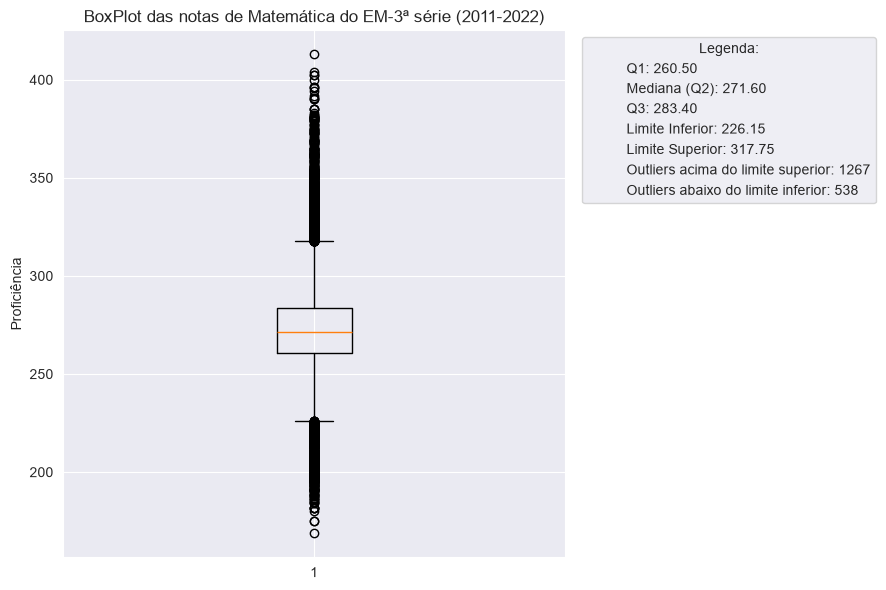

In [187]:
plt.figure(figsize=(9, 6))
x=df_unificado.loc[df_unificado['SERIE_ANO']=='EM-3ª série','MEDPROF-N']

Q1 = x.quantile(0.25)
Q3 = x.quantile(0.75)
IQR = Q3 - Q1
Q2=x.median()

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = x[(x < limite_inferior) | (x > limite_superior)]

outliers_acima = (x > limite_superior).sum()
outliers_abaixo = (x < limite_inferior).sum()

plt.boxplot(x)

plt.title("BoxPlot das notas de Matemática do EM-3ª série (2011-2022)")
plt.ylabel('Proficiência')

plt.plot([], [], ' ', label=f'Q1: {Q1:.2f}')
plt.plot([], [], ' ', label=f'Mediana (Q2): {Q2:.2f}')
plt.plot([], [], ' ', label=f'Q3: {Q3:.2f}')
plt.plot([], [], ' ', label=f'Limite Inferior: {limite_inferior:.2f}')
plt.plot([], [], ' ', label=f'Limite Superior: {limite_superior:.2f}')
plt.plot([], [], ' ', label=f'Outliers acima do limite superior: {outliers_acima}')
plt.plot([], [], ' ', label=f'Outliers abaixo do limite inferior: {outliers_abaixo}')

plt.legend(title='Legenda:',loc='upper left', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.savefig(
 'BoxPlot das notas de Matemática do EM-3ª série (2011-2022).png',
 dpi=300,
 bbox_inches='tight',
 facecolor='white'
)
plt.show()

In [180]:
for i, df in enumerate(list_proficiencia_saresp):
    print(f'\nAno: {2011 + i}')

    colunas = {c.upper(): c for c in df.columns}

    if 'DS_COMP' in colunas:
        coluna = colunas['DS_COMP']

        contagem = df[coluna].astype(str).str.strip().str.upper().value_counts()

        print('Matemática:', contagem.get('MATEMÁTICA', 0))
        print('Língua Portuguesa:', contagem.get('LÍNGUA PORTUGUESA', 0))


Ano: 2011
Matemática: 40399
Língua Portuguesa: 40399

Ano: 2012
Matemática: 40355
Língua Portuguesa: 40355

Ano: 2013
Matemática: 39098
Língua Portuguesa: 39098

Ano: 2014
Matemática: 46415
Língua Portuguesa: 46415

Ano: 2015
Matemática: 31857
Língua Portuguesa: 31857

Ano: 2016
Matemática: 30059
Língua Portuguesa: 30059

Ano: 2017
Matemática: 28444
Língua Portuguesa: 28444

Ano: 2018
Matemática: 10191
Língua Portuguesa: 10191

Ano: 2019
Matemática: 0
Língua Portuguesa: 0

Ano: 2020
Matemática: 25279
Língua Portuguesa: 25279

Ano: 2021
Matemática: 32141
Língua Portuguesa: 32141

Ano: 2022
Matemática: 37448
Língua Portuguesa: 37448

Ano: 2023
Matemática: 37160
Língua Portuguesa: 37160

Ano: 2024
Matemática: 38262
Língua Portuguesa: 38262


In [181]:
for i, df in enumerate(list_proficiencia_saresp):
    print(f'\nAno: {2011 + i}')

    colunas = {c.upper(): c for c in df.columns}

    if 'DS_COMP' in colunas and 'SERIE_ANO' in colunas:
        coluna_comp = colunas['DS_COMP']
        coluna_serie = colunas['SERIE_ANO']

        contagem = pd.crosstab(
            df[coluna_serie].astype(str).str.strip(),
            df[coluna_comp].astype(str).str.strip().str.upper()
        )

        print(contagem)


Ano: 2011
DS_COMP      GEOGRAFIA  HISTÓRIA  LÍNGUA PORTUGUESA  MATEMÁTICA
SERIE_ANO                                                      
5º Ano EF            0         0              11271       11271
7º Ano EF        10029     10029              10029       10029
9º Ano EF         9968      9968               9968        9968
EM-3ª série       9131      9131               9131        9131

Ano: 2012
DS_COMP      CIÊNCIAS  LÍNGUA PORTUGUESA  MATEMÁTICA
SERIE_ANO                                           
5º Ano EF           0              11048       11048
7º Ano EF       10034              10034       10034
9º Ano EF       10049              10049       10049
EM-3ª série      9224               9224        9224

Ano: 2013
DS_COMP      GEOGRAFIA  HISTÓRIA  LÍNGUA PORTUGUESA  MATEMÁTICA
SERIE_ANO                                                      
5º Ano EF            0         0              10301       10301
7º Ano EF         9754      9754               9754        9754
9º Ano EF